# Roads, loads and warehouse capacity

Read a saved road path and recalculate a published trade for different loads and vehicles.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

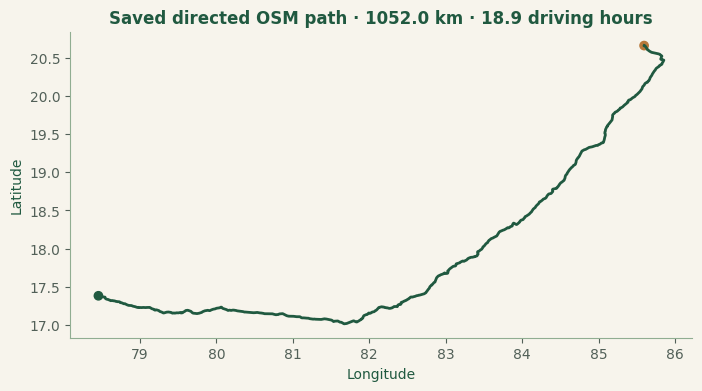

In [2]:
from Code.intelligence import service
routes = pd.read_parquet(INTEL / "phase3/roads_v1/routes.parquet")
road = routes[routes.road_km > 0].sort_values("road_km").iloc[len(routes)//2]
line = np.asarray(json.loads(road.geometry) if isinstance(road.geometry,str) else road.geometry, dtype=float)
fig, ax = plt.subplots(layout="constrained")
ax.plot(line[:,1],line[:,0],lw=2)
ax.scatter(line[[0,-1],1],line[[0,-1],0],c=[FOREST,GOLD])
ax.set(title=f"Saved directed OSM path · {road.road_km:.1f} km · {road.road_hours:.1f} driving hours",
       xlabel="Longitude",ylabel="Latitude",aspect="equal")
plt.show()

plan, _ = planned_trade()
buy = {**plan["buy"], "predicted_price": plan["buy"]["predicted_modal_price"]}
sell = {**plan["sell"], "predicted_price": plan["sell"]["predicted_modal_price"]}
facilities = [w for w in service.warehouses() if plan["crop"] in w["supported_crops"]]
warehouse = min(facilities, key=lambda w: service.distance(buy["coordinate"],{"lat":w["latitude"],"lng":w["longitude"]})) if facilities else None

In [3]:
def logistics(quantity, truck, days):
    route = service.calculate(buy,sell,quantity,truck,service.CONFIG["handling_rs_q"],plan["handling_loss_pct"],planned=True)
    display(pd.Series({"Payload (q)":route["payload_q"],"Trips":route["trips"],"Road estimate (km)":route["route"]["km"],
        "Driving per outbound trip (h)":route["route"]["base_hours"],"Modeled freight (₹)":route["transport"]}).to_frame("Direct journey"))
    if not warehouse:
        print("No compatible facility in the local inventory.")
        return
    fit = service.allocation(warehouse,[{"crop":plan["crop"],"quantity_q":quantity,"days":days}]*2)
    print(warehouse["name"], "·", fit["available_t"], "t simulated free · Two simultaneous loads fit:", fit["feasible"])
    if fit["rows"][0]["fits_alone"] and fit["rows"][0]["duration_ok"]:
        stored = service.calculate(buy,sell,quantity,truck,service.CONFIG["handling_rs_q"],plan["handling_loss_pct"],days,warehouse,planned=True)
        display(pd.Series({"Storage days":days,"Charge (₹)":stored["storage"],"Storage loss (%)":stored["storage_loss_pct"],
            "Total loss (%)":stored["loss_pct"],"Transport via storage (₹)":stored["transport"]}).round(2).to_frame("One load via warehouse"))

controls(logistics, quantity=[100,40,180,320], truck=list(service.CONFIG["vehicles"]), days=[7,14,30])

,Direct journey
Payload (q),40.00
Trips,3.00
Road estimate (km),1049.00
Driving per outbound trip (h),21.65
Modeled freight (₹),115390.00


cold storage · 702.0 t simulated free · Two simultaneous loads fit: True


,One load via warehouse
Storage days,7.00
Charge (₹),2100.00
Storage loss (%),0.56
Total loss (%),3.04
Transport via storage (₹),167015.46


interactive(children=(Dropdown(description='Quantity', options=(100, 40, 180, 320), value=100), Dropdown(descr…

Geometry comes from saved OpenStreetMap paths. Facility capacity and charges are simulated. Where a route lacks saved geometry, the calculator can use a labeled distance estimate. No live traffic or toll feed enters this example.

**Takeaway** · Truck capacity changes trips and freight. Warehouse capacity is shared across simultaneous loads.

**Next** · Combine timing and storage economics in Notebook 12.